# E-commerce: RFM, churn e previsão de vendas

**Pergunta de negócio:** como segmentar os clientes por valor e engajamento, estimar quais clientes podem ficar 90 dias sem comprar e prever vendas diárias de curto prazo com uma comparação temporal justa?

## Dados, fonte e preparação

A base é **Online Retail** do [UCI Machine Learning Repository](https://archive.ics.uci.edu/dataset/352/online+retail), transações de uma varejista britânica online entre **01/12/2010 e 09/12/2011**. A ficha do UCI informa licença **CC BY 4.0**. O arquivo local `data.csv` é a cópia tabular distribuída com o projeto.

A leitura seleciona somente colunas usadas. Datas são convertidas com o formato mês/dia/ano da base. Linhas sem `CustomerID` não entram em análises de cliente; devoluções são identificadas por `InvoiceNo` iniciado por `C` ou `Quantity` negativa e separadas da venda bruta. Receita líquida subtrai as devoluções. Linhas com preço ou quantidade não positivos são excluídas do conjunto de vendas, mas as devoluções são quantificadas antes desse filtro.

In [1]:
import logging
logging.getLogger("prophet.plot").disabled = True  # aviso de plotly opcional, sem efeito aqui
logging.getLogger("cmdstanpy").disabled = True  # logs INFO do Stan
from IPython.display import display
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
sys.path.insert(0, str(Path.cwd().parents[1] / 'scripts'))
from formatacao_br import fmt_int, fmt_num, fmt_brl, fmt_pct, tabela_br, formatar_eixos
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, average_precision_score, recall_score
from sklearn.model_selection import train_test_split
from prophet import Prophet

SEED = 42
ARQUIVO = Path("data.csv")
COLUNAS = ["InvoiceNo", "StockCode", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID", "Country"]
raw = pd.read_csv(ARQUIVO, encoding="ISO-8859-1", usecols=COLUNAS, dtype={"InvoiceNo":"string", "StockCode":"string", "CustomerID":"Float64", "Country":"category"})
raw["InvoiceDate"] = pd.to_datetime(raw["InvoiceDate"], format="%m/%d/%Y %H:%M", errors="coerce")
raw["InvoiceNo"] = raw["InvoiceNo"].astype("string")
raw["is_return"] = raw["InvoiceNo"].str.startswith("C", na=False) | raw["Quantity"].lt(0)
raw["amount"] = raw["Quantity"] * raw["UnitPrice"]

periodo_inicio, periodo_fim = raw["InvoiceDate"].min(), raw["InvoiceDate"].max()
qtd_linhas = len(raw)
qtd_devolucoes = int(raw["is_return"].sum())
qtd_sem_cliente = int(raw["CustomerID"].isna().sum())
returns = raw.loc[raw["is_return"]].copy()
sales = raw.loc[~raw["is_return"] & raw["CustomerID"].notna() & raw["InvoiceDate"].notna() & raw["UnitPrice"].gt(0) & raw["Quantity"].gt(0)].copy()
sales["CustomerID"] = sales["CustomerID"].astype("int64")
print(f"Linhas: {fmt_int(qtd_linhas)} | período: {periodo_inicio:%d/%m/%Y}–{periodo_fim:%d/%m/%Y}")
print(f"Devoluções/cancelamentos identificados: {fmt_int(qtd_devolucoes)} ({fmt_pct(qtd_devolucoes/qtd_linhas, 1)}); sem CustomerID: {fmt_int(qtd_sem_cliente)}")
print(f"Vendas válidas com cliente: {fmt_int(len(sales))}; receita bruta: £{fmt_num(sales.amount.sum(), 2)}; devoluções: £{fmt_num(returns.amount.sum(), 2)}; líquida: £{fmt_num(sales.amount.sum()+returns.amount.sum(), 2)}")

Linhas: 541.909 | período: 01/12/2010–09/12/2011
Devoluções/cancelamentos identificados: 10.624 (2,0%); sem CustomerID: 135.080
Vendas válidas com cliente: 397.884; receita bruta: £8.911.407,90; devoluções: £-896.812,49; líquida: £8.014.595,41


O resumo acima documenta o recorte efetivamente carregado e a dimensão da limpeza. O conjunto `sales` representa compras identificáveis por cliente; os valores devolvidos ficam em `returns`, permitindo reportar receita líquida sem contaminar frequência e recência de compra.

## Receita e comportamento mensal

A série mostra receita líquida por mês civil, com devoluções contabilizadas no mês da própria transação. Isso ajuda a localizar a concentração sazonal, mas o período curto não sustenta extrapolações anuais.

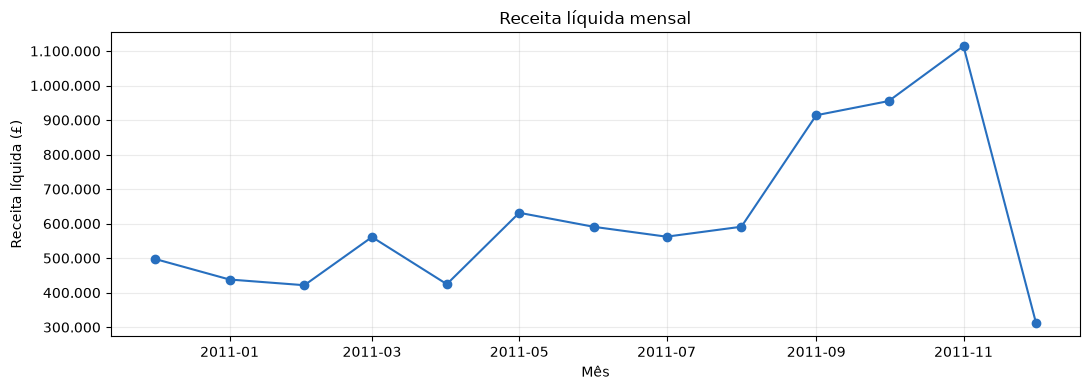

Maior mês líquido: 11/2011 (£1.114.077)


In [2]:
monthly = sales.set_index("InvoiceDate").resample("MS")["amount"].sum().add(returns.set_index("InvoiceDate").resample("MS")["amount"].sum(), fill_value=0)
monthly.index = monthly.index.to_period("M").to_timestamp()
fig, ax = plt.subplots(figsize=(11,4))
ax.plot(monthly.index, monthly.values, marker="o", color="#276FBF")
ax.set(title="Receita líquida mensal", xlabel="Mês", ylabel="Receita líquida (£)")
ax.grid(alpha=.25); formatar_eixos(fig); fig.tight_layout(); plt.show()
print("Maior mês líquido:", monthly.idxmax().strftime("%m/%Y"), f"(£{fmt_num(monthly.max(), 0)})")

O pico mensal indica quando a operação concentrou maior faturamento líquido nesta amostra. O próximo recorte muda a unidade para cliente e usa apenas vendas válidas; portanto, os segmentos descrevem comportamento de compra, não saldo contábil.

## RFM e coortes de retenção

Recência é medida em dias até o último dia observado; frequência conta faturas distintas; valor é gasto bruto em compras válidas. Os quintis de R, F e M formam segmentos interpretáveis. A coorte é o mês da primeira compra; retenção é a fração de clientes daquela coorte que volta a comprar em cada mês subsequente.

Clientes analisados: 4.338


,clientes,gasto_medio,recencia_mediana
segmento,,,
Em risco de inatividade,1.735,"780,6","180,0"
Oportunidade de desenvolver,1.158,"760,7","31,0"
Campeões,946,"6.088,2","11,0"
Frequentes,499,"1.837,2","39,0"


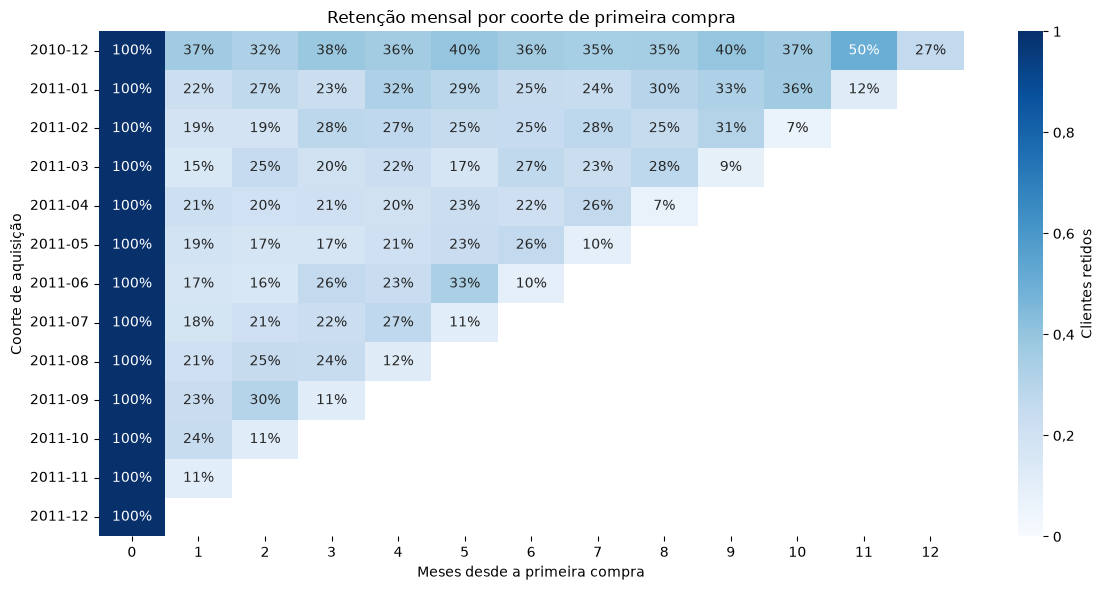

Participação de campeões: 21,8%
Retenção média no mês seguinte: 20,6%


In [3]:
data_ref = sales.InvoiceDate.max().normalize() + pd.Timedelta(days=1)
rfm = sales.groupby("CustomerID").agg(
    ultima_compra=("InvoiceDate", "max"),
    frequencia=("InvoiceNo", "nunique"),
    valor=("amount", "sum"),
    primeira_compra=("InvoiceDate", "min"),
)
rfm["recencia_dias"] = (data_ref - rfm.ultima_compra.dt.normalize()).dt.days
rfm["R"] = pd.qcut(rfm.recencia_dias.rank(method="first"), 5, labels=[5,4,3,2,1]).astype(int)
rfm["F"] = pd.qcut(rfm.frequencia.rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["M"] = pd.qcut(rfm.valor.rank(method="first"), 5, labels=[1,2,3,4,5]).astype(int)
rfm["segmento"] = np.select([rfm.R.ge(4)&rfm.F.ge(4)&rfm.M.ge(4), rfm.R.le(2), rfm.F.ge(4)], ["Campeões", "Em risco de inatividade", "Frequentes"], default="Oportunidade de desenvolver")
print("Clientes analisados:", fmt_int(len(rfm)))
display(tabela_br(rfm.groupby("segmento", observed=True).agg(clientes=("valor","size"), gasto_medio=("valor","mean"), recencia_mediana=("recencia_dias","median")).sort_values("clientes", ascending=False), casas=1))

cohort = sales[["CustomerID", "InvoiceDate"]].copy()
cohort["mes_compra"] = cohort.InvoiceDate.dt.to_period("M")
cohort["coorte"] = cohort.groupby("CustomerID").mes_compra.transform("min")
cohort["idade_coorte"] = (cohort.mes_compra - cohort.coorte).apply(lambda z: z.n)
cohort_sizes = cohort.groupby("coorte").CustomerID.nunique()
retencao = cohort.groupby(["coorte", "idade_coorte"]).CustomerID.nunique().unstack().div(cohort_sizes, axis=0)
fig, ax = plt.subplots(figsize=(12,6))
sns.heatmap(retencao, cmap="Blues", annot=retencao.map(lambda v: fmt_pct(v, 0)), fmt="", vmin=0, vmax=1, ax=ax, cbar_kws={"label":"Clientes retidos"})
ax.set(title="Retenção mensal por coorte de primeira compra", xlabel="Meses desde a primeira compra", ylabel="Coorte de aquisição")
formatar_eixos(fig); fig.tight_layout(); plt.show()
print("Participação de campeões:", f"{fmt_pct(rfm.segmento.eq('Campeões').mean(), 1)}")
print("Retenção média no mês seguinte:", f"{fmt_pct(retencao.loc[retencao.index < retencao.index.max(), 1].mean(), 1)}")

O mapa de coortes mostra que proporção dos clientes reaparece após a primeira compra, controlando o mês de aquisição. Valores nas últimas colunas estão ausentes quando a coorte ainda não teve tempo de maturar. A tabela RFM sugere quais grupos merecem ações distintas: retenção para campeões e reativação para clientes há mais tempo sem comprar.

## Churn: corte temporal e avaliação sem vazamento

O corte **T = data máxima − 90 dias** define a observação. Features usam somente compras com data até T. O rótulo vale 1 para clientes sem compra em (T, data máxima]. O universo inclui clientes com compra até T; quem não retorna na janela é o evento positivo.

Para evitar um teste aleatório de clientes que mascara o tempo, avaliamos um holdout temporal por última compra observada até T: 25% mais recentes ficam no teste e os demais no treino. Comparamos um modelo de árvore boosting com uma baseline de recência (maior risco quanto maior a recência). ROC-AUC, PR-AUC e recall no limiar 0,5 são reportados no mesmo teste. Recência por si só pode carregar sinal forte; a baseline torna esse ganho visível.

In [4]:
T = sales.InvoiceDate.max().normalize() - pd.Timedelta(days=90)
obs = sales.loc[sales.InvoiceDate.le(T)].copy()
future_ids = set(sales.loc[sales.InvoiceDate.gt(T), "CustomerID"].unique())
base = obs.groupby("CustomerID").agg(
    ultima=("InvoiceDate", "max"), frequencia=("InvoiceNo", "nunique"),
    gasto=("amount", "sum"), ticket_medio=("amount", "mean"),
    itens_medio=("Quantity", "mean"), produtos=("StockCode", "nunique"),
)
base["recencia"] = (T - base.ultima.dt.normalize()).dt.days
base["churn"] = (~base.index.isin(future_ids)).astype(int)
base["ultima_ordem"] = base.ultima
base = base.sort_values("ultima_ordem")
features = ["recencia", "frequencia", "gasto", "ticket_medio", "itens_medio", "produtos"]
split = int(len(base)*.75)
train, test = base.iloc[:split], base.iloc[split:]
model = make_pipeline(SimpleImputer(strategy="median"), HistGradientBoostingClassifier(max_iter=100, learning_rate=.08, max_leaf_nodes=15, random_state=SEED))
model.fit(train[features], train.churn)
prob_model = model.predict_proba(test[features])[:,1]
prob_recencia = test.recencia.rank(pct=True).to_numpy()
y_test = test.churn.to_numpy()
limiar = .5
metricas = pd.DataFrame({
    "ROC-AUC": [roc_auc_score(y_test, prob_recencia), roc_auc_score(y_test, prob_model)],
    "PR-AUC": [average_precision_score(y_test, prob_recencia), average_precision_score(y_test, prob_model)],
    "Recall (limiar 0,5)": [recall_score(y_test, prob_recencia >= limiar), recall_score(y_test, prob_model >= limiar)],
}, index=["Baseline: recência", "HistGradientBoosting"])
print(f"T={T:%d/%m/%Y} | clientes: {fmt_int(len(base))} | prevalência de churn: {fmt_pct(base.churn.mean(), 1)} | teste: {fmt_int(len(test))}")
display(tabela_br(metricas, casas=3))
print("Melhora de PR-AUC sobre baseline:", f"{('+' if (metricas.loc['HistGradientBoosting','PR-AUC']-metricas.loc['Baseline: recência','PR-AUC']) >= 0 else '') + fmt_num(metricas.loc['HistGradientBoosting','PR-AUC']-metricas.loc['Baseline: recência','PR-AUC'], 3)}")

T=10/09/2011 | clientes: 3.370 | prevalência de churn: 43,0% | teste: 843


,ROC-AUC,PR-AUC,"Recall (limiar 0,5)"
Baseline: recência,"0,542","0,266","0,541"
HistGradientBoosting,"0,775","0,462","0,512"


Melhora de PR-AUC sobre baseline: +0,196


A avaliação usa um único período futuro e mantém a mesma população de teste para as duas abordagens. A PR-AUC é especialmente útil quando o evento de churn é desbalanceado; o recall no limiar 0,5 depende da calibração e não deve ser interpretado como uma política ótima de contato. O modelo só é valioso se superar recência de forma consistente em novos períodos, algo que um ano de dados não permite confirmar.

## Previsão diária: Prophet contra sazonal ingênua

Os últimos 30 dias observados formam o holdout, excluídos do ajuste. A baseline prevê cada dia usando o valor do mesmo dia da semana anterior. Dias sem vendas são preenchidos com zero e incluídos tanto no Prophet quanto na baseline. MAPE exclui dias reais iguais a zero, pois a divisão é indefinida; também reportamos a quantidade desses dias. O Prophet recebe apenas a janela de treino e sazonalidade semanal, sem ajuste no holdout.

In [5]:
daily = sales.set_index("InvoiceDate").resample("D").amount.sum().add(returns.set_index("InvoiceDate").resample("D").amount.sum(), fill_value=0).asfreq("D", fill_value=0)
last_day = daily.index.max().normalize()
hold_start = last_day - pd.Timedelta(days=29)
train_daily = daily.loc[daily.index < hold_start]
test_daily = daily.loc[daily.index >= hold_start]
prophet_train = train_daily.rename_axis("ds").reset_index(name="y")
pmodel = Prophet(weekly_seasonality=True, yearly_seasonality=False, daily_seasonality=False, uncertainty_samples=0)
pmodel.fit(prophet_train)
pred = pmodel.predict(pd.DataFrame({"ds":test_daily.index})).set_index("ds")["yhat"].reindex(test_daily.index)
naive = daily.reindex(test_daily.index - pd.Timedelta(days=7)).to_numpy()
naive = pd.Series(naive, index=test_daily.index)
def erros(real, previsto):
    mae = np.mean(np.abs(real.to_numpy()-previsto.to_numpy()))
    mask = real.ne(0)
    mape = np.mean(np.abs((real[mask]-previsto[mask])/real[mask]))*100
    return mae, mape
mae_p, mape_p = erros(test_daily, pred)
mae_n, mape_n = erros(test_daily, naive)
zeros_holdout = int(test_daily.eq(0).sum())
print(f"Holdout: {hold_start:%d/%m/%Y}–{last_day:%d/%m/%Y} | dias zero: {zeros_holdout}/{len(test_daily)}")
display(tabela_br(pd.DataFrame({"MAE (£)": [mae_n,mae_p], "MAPE (%)": [mape_n,mape_p]}, index=["Ingênua (mesmo dia semana anterior)","Prophet"])))
print("Vencedor pelo MAE:", "Prophet" if mae_p < mae_n else "baseline ingênua")

Holdout: 10/11/2011–09/12/2011 | dias zero: 4/30


,MAE (£),MAPE (%)
Ingênua (mesmo dia semana anterior),"11.847,54","37,89"
Prophet,"10.759,04","26,98"


Vencedor pelo MAE: Prophet


No gráfico, as previsões de ambos os métodos são comparadas com a série real nos mesmos 30 dias. A decisão sobre o método é baseada nas métricas de holdout: se o Prophet perde para a regra sazonal, a conclusão é manter a regra simples até haver evidência em novas janelas temporais.

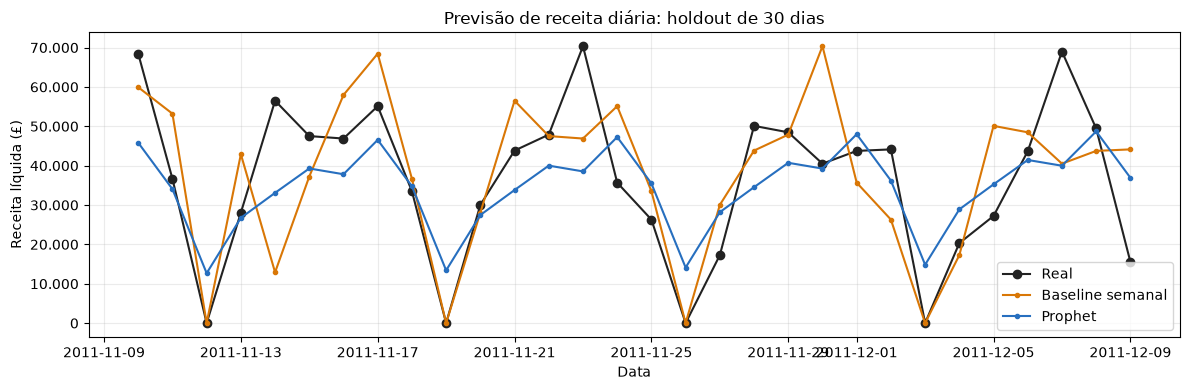

In [6]:
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(test_daily.index, test_daily, marker="o", label="Real", color="#222222")
ax.plot(test_daily.index, naive, marker=".", label="Baseline semanal", color="#D97706")
ax.plot(test_daily.index, pred, marker=".", label="Prophet", color="#276FBF")
ax.set(title="Previsão de receita diária: holdout de 30 dias", xlabel="Data", ylabel="Receita líquida (£)")
ax.legend(); ax.grid(alpha=.25); formatar_eixos(fig); fig.tight_layout(); plt.show()

## Principais achados

Os indicadores abaixo são calculados a partir das etapas anteriores, para que o texto permaneça sincronizado com os dados executados.

In [7]:
print(f"• {fmt_int(len(sales))} linhas de compra identificáveis após limpeza, de {periodo_inicio:%d/%m/%Y} a {periodo_fim:%d/%m/%Y}; {fmt_int(qtd_devolucoes)} linhas de devolução/cancelamento foram separadas.")
print(f"• Receita líquida no período: £{fmt_num(sales.amount.sum()+returns.amount.sum(), 0)}; pico mensal em {monthly.idxmax():%m/%Y} (£{fmt_num(monthly.max(), 0)}).")
print(f"• Segmento Campeões: {fmt_int((rfm.segmento=='Campeões').sum())} clientes ({fmt_pct(rfm.segmento.eq('Campeões').mean(), 1)}); retenção média no mês seguinte: {fmt_pct(retencao.loc[retencao.index < retencao.index.max(),1].mean(), 1)}.")
print(f"• Churn (T={T:%d/%m/%Y}): prevalência {fmt_pct(base.churn.mean(), 1)}; PR-AUC baseline {fmt_num(metricas.iloc[0,1], 3)} e modelo {fmt_num(metricas.iloc[1,1], 3)} (ROC-AUC {fmt_num(metricas.iloc[1,0], 3)}; recall {fmt_pct(metricas.iloc[1,2], 1)}).")
print(f"• Forecast 30 dias: MAE Prophet £{fmt_num(mae_p, 0)} vs baseline £{fmt_num(mae_n, 0)}; MAPE {fmt_num(mape_p, 1)}% vs {fmt_num(mape_n, 1)}%. Melhor pelo MAE: {'Prophet' if mae_p < mae_n else 'baseline ingênua'}.")

• 397.884 linhas de compra identificáveis após limpeza, de 01/12/2010 a 09/12/2011; 10.624 linhas de devolução/cancelamento foram separadas.
• Receita líquida no período: £8.014.595; pico mensal em 11/2011 (£1.114.077).
• Segmento Campeões: 946 clientes (21,8%); retenção média no mês seguinte: 20,6%.
• Churn (T=10/09/2011): prevalência 43,0%; PR-AUC baseline 0,266 e modelo 0,462 (ROC-AUC 0,775; recall 51,2%).
• Forecast 30 dias: MAE Prophet £10.759 vs baseline £11.848; MAPE 27,0% vs 37,9%. Melhor pelo MAE: Prophet.


## Limitações e próximos passos

A base cobre cerca de um ano e termina em dezembro de 2011; coortes tardias têm acompanhamento curto e os resultados não representam necessariamente o varejo atual. IDs ausentes ficam fora do RFM e do churn. Devoluções são reconhecidas pelo prefixo `C` ou quantidade negativa; a receita é reconhecida pela data da linha de devolução, não conciliada à fatura original. Churn é uma definição operacional de 90 dias sem nova compra e o teste temporal é uma única janela. O modelo pode mudar com outra data de corte; validar em cortes sucessivos antes de usar para campanha. O forecast usa um holdout de 30 dias, com dias zero excluídos do MAPE, e não testa intervalos de previsão ou custos de erro. Próximos passos: backtesting por múltiplas janelas, segmentação por país e teste de campanhas de reativação.